## CartPole Skating

> **Problem**: If Peter wants to escape from the wolf, he needs to be able to move faster than him. We will see how Peter can learn to skate, in particular, to keep balance, using Q-Learning.

First, let's install the gym and import required libraries:

In [46]:
import sys
from IPython.display import clear_output, display
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import random


print(np.__version__)
print(gym.__version__)

2.4.6
1.3.0


## Create a cartpole environment

To work with a cartpole balancing problem, we need to initialize corresponding environment. Each environment is associated with an:

- Observation space that defines the structure of information that we receive from the environment. For cartpole problem, we receive position of the pole, velocity and some other values.

- Action space that defines possible actions. In our case the action space is discrete, and consists of two actions - left and right. 


In [ ]:
env = gym.make("CartPole-v1", render_mode="rgb_array")
print(env.action_space)
print(env.observation_space)
print(env.action_space.sample())

Discrete(2)
Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
1


To see how the environment works, let's run a short simulation for 100 steps.

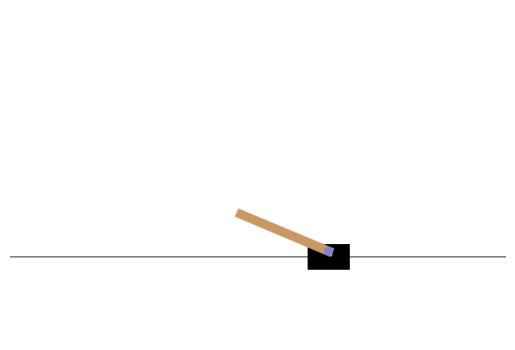

In [ ]:
obs, info = env.reset()

for _ in range(100):
    frame = env.render()

    clear_output(wait=True)
    plt.imshow(frame)
    plt.axis("off")
    display(plt.gcf())
    plt.close()

    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())

    if terminated or truncated:
        obs, info = env.reset()

env.close()

During simulation, we need to get observations in order to decide how to act. In fact, `step` function returns us back current observations, reward function, and the `done` flag that indicates whether it makes sense to continue the simulation or not:

The observation vector that is returned at each step of the simulation contains the following values:

- Position of cart
- Velocity of cart
- Angle of pole
- Rotation rate of pole

In [ ]:
env.reset()

done = False
while not done:
   env.render()
   obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
   print(f"{obs} -> {reward}")
env.close()

We can get min and max value of those numbers:

In [57]:
print(env.observation_space.low)
print(env.observation_space.high)

[-4.8               -inf -0.41887903        -inf]
[4.8               inf 0.41887903        inf]


## State Discretization

In Q-Learning, we need to build Q-Table that defines what to do at each state. To be able to do this, we need state to be discreet, more precisely, it should contain finite number of discrete values. Thus, we need somehow to discretize our observations, mapping them to a finite set of states.

There are a few ways we can do this:

- Divide into bins. If we know the interval of a certain value, we can divide this interval into a number of bins, and then replace the value by the bin number that it belongs to. This can be done using the numpy digitize method. In this case, we will precisely know the state size, because it will depend on the number of bins we select for digitalization.

- ✅ We can use linear interpolation to bring values to some finite interval (say, from -20 to 20), and then convert numbers to integers by rounding them. This gives us a bit less control on the size of the state, especially if we do not know the exact ranges of input values. For example, in our case 2 out of 4 values do not have upper/lower bounds on their values, which may result in the infinite number of states.

In our example, we will go with the second approach. As you may notice later, despite undefined upper/lower bounds, those value rarely take values outside of certain finite intervals, thus those states with extreme values will be very rare.

Here is the function that will take the observation from our model and produce a tuple of 4 integer values: 

In [77]:
def discretize(x):
    return tuple((x/np.array([0.25, 0.25, 0.01, 0.1])).astype(int))

Let's also explore other discretization method using bins:

In [65]:
def create_bins(i,num):
    return np.arange(num+1)*(i[1]-i[0])/num+i[0]

print("Sample bins for interval (-5,5) with 10 bins\n",create_bins((-5,5),10))

ints = [(-5,5),(-2,2),(-0.5,0.5),(-2,2)] # intervals of values for each parameter
nbins = [20,20,10,10] # number of bins for each parameter
bins = [create_bins(ints[i],nbins[i]) for i in range(4)]

def discretize_bins(x):
    return tuple(np.digitize(x[i],bins[i]) for i in range(4))

Sample bins for interval (-5,5) with 10 bins
 [-5. -4. -3. -2. -1.  0.  1.  2.  3.  4.  5.]


Let's now run a short simulation and observe those discrete environment values. Feel free to try both discretize and discretize_bins and see if there is a difference.

✅ discretize_bins returns the bin number, which is 0-based. Thus for values of input variable around 0 it returns the number from the middle of the interval (10). In discretize, we did not care about the range of output values, allowing them to be negative, thus the state values are not shifted, and 0 corresponds to 0

KeyboardInterrupt: 

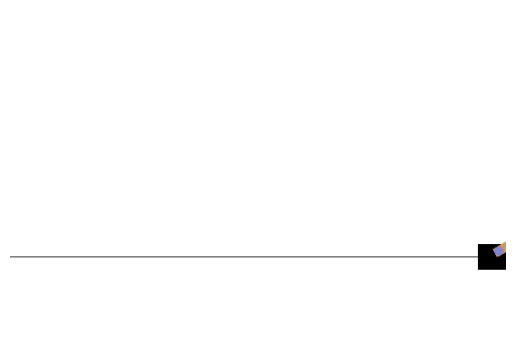

In [ ]:
env.reset()

done = False
while not done:
   frame = env.render()

   clear_output(wait=True)
   plt.imshow(frame)
   plt.axis("off")
   display(plt.gcf())
   plt.close()
   
   obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
   #print(discretize_bins(obs))
   print(discretize(obs))
env.close()

## Q-Table Structure

In our previous lesson, the state was a simple pair of numbers from 0 to 8, and thus it was convenient to represent Q-Table by a numpy tensor with a shape of 8x8x2. If we use bins discretization, the size of our state vector is also known, so we can use the same approach and represent state by an array of shape 20x20x10x10x2 (here 2 is the dimension of action space, and first dimensions correspond to the number of bins we have selected to use for each of the parameters in observation space).

However, sometimes precise dimensions of the observation space are not known. In case of the discretize function, we may never be sure that our state stays within certain limits, because some of the original values are not bound. Thus, we will use a slightly different approach and represent Q-Table by a dictionary.

Use the pair (state,action) as the dictionary key, and the value would correspond to Q-Table entry value. 

Here we also define a function qvalues(), which returns a list of Q-Table values for a given state that corresponds to all possible actions. If the entry is not present in the Q-Table, we will return 0 as the default.


In [ ]:
Q = {}
actions = (0,1)

def qvalues(state):
    return [Q.get((state,a),0) for a in actions]


## Let's Start Q-Learning!

Here, `alpha` is the learning rate that defines to which extent we should adjust the current values of Q-Table at each step. In the previous lesson we started with 1, and then decreased alpha to lower values during training. In this example we will keep it constant just for simplicity, and you can experiment with adjusting alpha values later.

`gamma` is the discount factor that shows to which extent we should prioritize future reward over current reward.

`epsilon` is the exploration/exploitation factor that determines whether we should prefer exploration to exploitation or vice versa. In our algorithm, we will in epsilon percent of the cases select the next action according to Q-Table values, and in the remaining number of cases we will execute a random action. This will allow us to explore areas of the search space that we have never seen before.

✅ In terms of balancing - choosing random action (exploration) would act as a random punch in the wrong direction, and the pole would have to learn how to recover the balance from those "mistakes"

In [72]:
# hyperparameters
alpha = 0.3
gamma = 0.9
epsilon = 0.90

We can also make two improvements to our algorithm from the previous lesson:

- `Calculate average cumulative reward`, over a number of simulations. We will print the progress each 5000 iterations, and we will average out our cumulative reward over that period of time. It means that if we get more than 195 point - we can consider the problem solved, with even higher quality than required.

- `Calculate maximum average cumulative result`, Qmax, and we will store the Q-Table corresponding to that result. When you run the training you will notice that sometimes the average cumulative result starts to drop, and we want to keep the values of Q-Table that correspond to the best model observed during training.

Collect all cumulative rewards at each simulation at rewards vector for further plotting.

In [78]:
def probs(v,eps=1e-4):
    v = v-v.min()+eps
    v = v/v.sum()
    return v

Qmax = 0
cum_rewards = []
rewards = []
for epoch in range(100000):
    obs, info = env.reset()
    truncated , terminated = False, False
    cum_reward=0
    # == do the simulation ==
    while not terminated and not truncated:
        s = discretize(obs)
        if random.random()<epsilon:
            # exploitation - chose the action according to Q-Table probabilities
            v = probs(np.array(qvalues(s)))
            a = random.choices(actions,weights=v)[0]
        else:
            # exploration - randomly chose the action
            a = np.random.randint(env.action_space.n)

        obs, reward, terminated, truncated, info = env.step(a)

        cum_reward+=reward
        ns = discretize(obs)
        Q[(s,a)] = (1 - alpha) * Q.get((s,a),0) + alpha * (reward + gamma * max(qvalues(ns)))
    cum_rewards.append(cum_reward)
    rewards.append(cum_reward)
    # == Periodically print results and calculate average reward ==
    if epoch%5000==0:
        print(f"{epoch}: {np.average(cum_rewards)}, alpha={alpha}, epsilon={epsilon}")
        if np.average(cum_rewards) > Qmax:
            Qmax = np.average(cum_rewards)
            Qbest = Q
        cum_rewards=[]

0: 12.0, alpha=0.3, epsilon=0.9
5000: 62.1904, alpha=0.3, epsilon=0.9
10000: 91.7378, alpha=0.3, epsilon=0.9
15000: 107.2002, alpha=0.3, epsilon=0.9
20000: 116.875, alpha=0.3, epsilon=0.9
25000: 130.2094, alpha=0.3, epsilon=0.9
30000: 132.815, alpha=0.3, epsilon=0.9
35000: 140.2322, alpha=0.3, epsilon=0.9
40000: 147.0082, alpha=0.3, epsilon=0.9
45000: 145.8366, alpha=0.3, epsilon=0.9
50000: 152.6708, alpha=0.3, epsilon=0.9
55000: 152.332, alpha=0.3, epsilon=0.9
60000: 148.544, alpha=0.3, epsilon=0.9
65000: 149.2008, alpha=0.3, epsilon=0.9
70000: 152.614, alpha=0.3, epsilon=0.9
75000: 147.6752, alpha=0.3, epsilon=0.9
80000: 148.5368, alpha=0.3, epsilon=0.9
85000: 148.702, alpha=0.3, epsilon=0.9
90000: 156.077, alpha=0.3, epsilon=0.9
95000: 156.0194, alpha=0.3, epsilon=0.9


What you may notice from those results:

Close to our goal. We are very close to achieving the goal of getting 195 cumulative rewards over 100+ consecutive runs of the simulation, or we may have actually achieved it! Even if we get smaller numbers, we still do not know, because we average over 5000 runs, and only 100 runs is required in the formal criteria.

Reward starts to drop. Sometimes the reward start to drop, which means that we can "destroy" already learnt values in the Q-Table with the ones that make the situation worse.

## Plotting Training Progress
During training, we have collected the cumulative reward value at each of the iterations into rewards vector. Here is how it looks when we plot it against the iteration number:

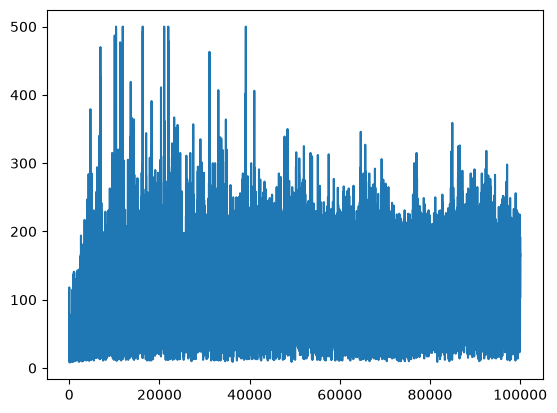

In [79]:
plt.plot(rewards)

From this graph, it is not possible to tell anything, because due to the nature of stochastic training process the length of training sessions varies greatly. To make more sense of this graph, we can calculate **running average** over series of experiments, let's say 100. This can be done conveniently using `np.convolve`:

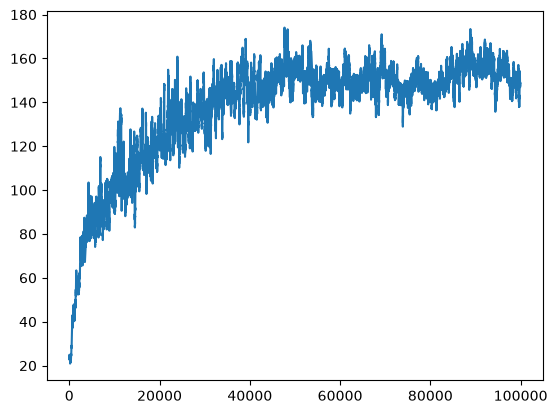

In [80]:
def running_average(x,window):
    return np.convolve(x,np.ones(window)/window,mode='valid')

plt.plot(running_average(rewards,100))

## Varying Hyperparameters and Seeing the Result in Action

Now it would be interesting to actually see how the trained model behaves. Let's run the simulation, and we will be following the same action selection strategy as during training: sampling according to the probability distribution in Q-Table: 

To make learning more stable, it makes sense to adjust some of our hyperparameters during training. In particular:

- For learning rate, alpha, we may start with values close to 1, and then keep decreasing the parameter. With time, we will be getting good probability values in the Q-Table, and thus we should be adjusting them slightly, and not overwriting completely with new values.

- Increase epsilon. We may want to increase the epsilon slowly, in order to explore less and exploit more. It probably makes sense to start with lower value of epsilon, and move up to almost 1.

Task 1: Play with hyperparameter values and see if you can achieve higher cumulative reward. Are you getting above 195?

Task 2: To formally solve the problem, you need to get 195 average reward across 100 consecutive runs. Measure that during training and make sure that you have formally solved the problem!

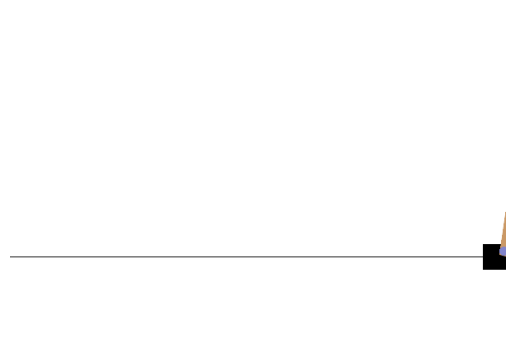

In [82]:
obs,info = env.reset()
truncated , terminated = False, False
while not terminated and not truncated:
   s = discretize(obs)
   frame = env.render()

   clear_output(wait=True)
   plt.imshow(frame)
   plt.axis("off")
   display(plt.gcf())
   plt.close()
   
   v = probs(np.array(qvalues(s)))
   a = random.choices(actions,weights=v)[0]
   obs, reward, terminated, truncated, info = env.step(a)

env.close()


## Saving result to an animated GIF

If you want to impress your friends, you may want to send them the animated GIF picture of the balancing pole. To do this, we can invoke `env.render` to produce an image frame, and then save those to animated GIF using PIL library:

In [ ]:
from PIL import Image
obs = env.reset()
done = False
i=0
ims = []
while not done:
   s = discretize(obs)
   img=env.render(mode='rgb_array')
   ims.append(Image.fromarray(img))
   v = probs(np.array([Qbest.get((s,a),0) for a in actions]))
   a = random.choices(actions,weights=v)[0]
   obs,_,done,_ = env.step(a)
   i+=1
env.close()
ims[0].save('images/cartpole-balance.gif',save_all=True,append_images=ims[1::2],loop=0,duration=5)
print(i)

360
